# AA3 · Parcial II · Cuaderno 2: Embeddings
**Alumno:** Emilio Frausto
**Datos:** reseñas de Amazon en español, `mteb/amazon_reviews_multi` (config `es`): https://huggingface.co/datasets/mteb/amazon_reviews_multi

La idea: comparar dos formas de predecir las estrellas de una reseña. Los bigramas solo ven qué palabras aparecen, y la Bi-LSTM también ve en qué orden.

### Importaciones

In [1]:
import os
import importlib.util

en_colab = importlib.util.find_spec("google.colab") is not None
os.environ["KERAS_BACKEND"] = "tensorflow" if en_colab else "torch"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import keras
import tensorflow as tf  # TextVectorization y tf.data lo necesitan
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)
pd.set_option("display.max_colwidth", 200)
print("Backend:", keras.backend.backend())

Backend: torch


## 1. Datos
Uso [reseñas de Amazon en español](https://huggingface.co/datasets/mteb/amazon_reviews_multi). Cada reseña tiene de 1 a 5 estrellas, así que son **5 clases** y vienen balanceadas.

Las reglas son iguales para los dos modelos:
- Divido el `train` de Hugging Face 80/20 con semilla.
- La prueba es el `test` de Hugging Face y solo la uso una vez.
- El vocabulario sale solo del entrenamiento.

In [2]:
url = "https://huggingface.co/datasets/mteb/amazon_reviews_multi/resolve/refs%2Fconvert%2Fparquet/es/"
df_hf = pd.read_parquet(url + "train/0000.parquet")[["text", "label"]]
df_test = pd.read_parquet(url + "test/0000.parquet")[["text", "label"]]

# revuelvo con semilla y separo 80/20
df_hf = df_hf.sample(frac=1, random_state=SEED).reset_index(drop=True)
n_val = int(0.2 * len(df_hf))
df_val, df_train = df_hf.iloc[:n_val], df_hf.iloc[n_val:]

CLASES = ["1 estrella", "2 estrellas", "3 estrellas", "4 estrellas", "5 estrellas"]
print(f"Ejemplos: {len(df_hf) + len(df_test):,} · Clases: {len(CLASES)}")
print(f"Entrenamiento: {len(df_train):,} · Validacion: {len(df_val):,} · Prueba: {len(df_test):,}")
df_train["label"].value_counts().sort_index()

Ejemplos: 205,000 · Clases: 5
Entrenamiento: 160,000 · Validacion: 40,000 · Prueba: 5,000


label
0    32016
1    31991
2    32068
3    32001
4    31924
Name: count, dtype: int64

In [3]:
# los paso a tf.data en lotes de 32
def a_dataset(df, mezclar=False):
    ds = tf.data.Dataset.from_tensor_slices((df["text"].values, df["label"].values.astype("int32")))
    if mezclar:
        ds = ds.shuffle(10_000, seed=SEED)
    return ds.batch(32)

train_ds, val_ds, test_ds = a_dataset(df_train, mezclar=True), a_dataset(df_val), a_dataset(df_test)
textos_train = train_ds.map(lambda x, y: x)  # solo los textos, para sacar el vocabulario

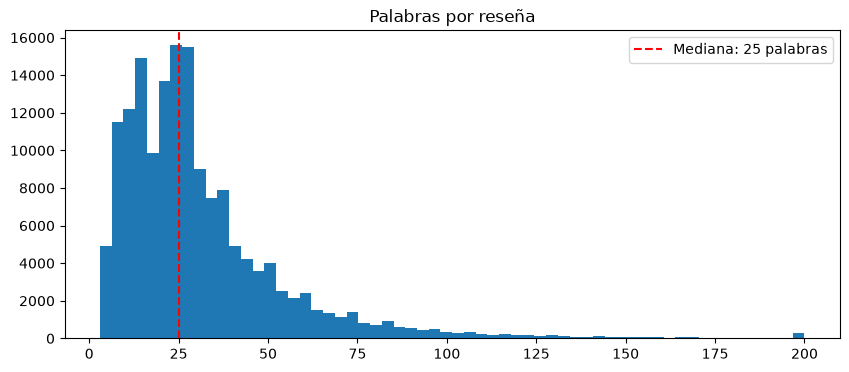

Cociente = 160,000 / 25 = 6,400
Segun la regla gana: secuencia


In [4]:
# cociente = muestras / mediana de palabras
longitudes = df_train["text"].str.split().str.len().values
mediana = np.median(longitudes)
cociente = len(longitudes) / mediana

plt.figure(figsize=(10, 4))
plt.hist(np.clip(longitudes, 0, 200), bins=60)
plt.axvline(mediana, color="red", linestyle="--", label=f"Mediana: {mediana:.0f} palabras")
plt.title("Palabras por reseña")
plt.legend()
plt.show()

print(f"Cociente = {len(longitudes):,} / {mediana:.0f} = {cociente:,.0f}")
print("Segun la regla gana:", "bigramas" if cociente < 1500 else "secuencia")

> **Mi predicción, escrita antes de entrenar:** Yo esperaria que Bi-LSTM salga con un menor error que los Bigramas, 
mas que nada por el contexto cronologico que podria entender el Bi-LSTM por sus indices y embeddings

## 2. Línea base
Bigramas como en la práctica 4. Como aquí son 5 clases, cambié la salida a softmax y la pérdida a `sparse_categorical_crossentropy`.

Epoch 1/10


C:\Users\efrau\OneDrive\Documents\UNIVERSIDAD\SEPTIMO\ML3\ml3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


5000/5000 - 80s - 16ms/step - accuracy: 0.4743 - loss: 1.2081 - val_accuracy: 0.5488 - val_loss: 1.0628


Epoch 2/10


5000/5000 - 80s - 16ms/step - accuracy: 0.5079 - loss: 1.1616 - val_accuracy: 0.5454 - val_loss: 1.0844


Epoch 3/10


5000/5000 - 86s - 17ms/step - accuracy: 0.5101 - loss: 1.1626 - val_accuracy: 0.5469 - val_loss: 1.0906


Epoch 4/10


5000/5000 - 79s - 16ms/step - accuracy: 0.5110 - loss: 1.1651 - val_accuracy: 0.5426 - val_loss: 1.0989


Bigramas: exactitud de prueba 0.553


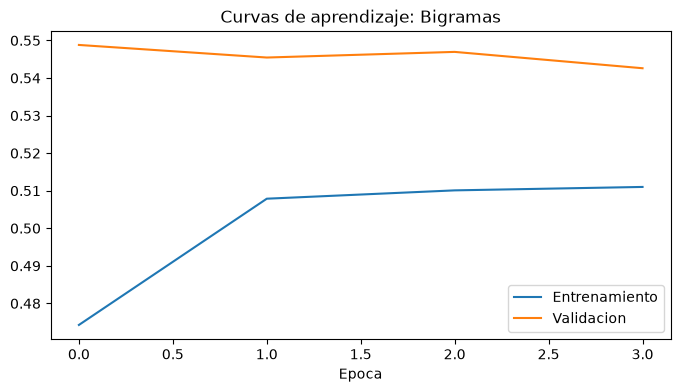

In [5]:
def vectorizar(ds, vectorizador, cache=False):
    ds = ds.map(lambda x, y: (vectorizador(x), y), num_parallel_calls=tf.data.AUTOTUNE)
    return (ds.cache() if cache else ds).prefetch(tf.data.AUTOTUNE)


registro = {}

def entrenar(nombre, familia, modelo, ds_train, ds_val, ds_test):
    modelo.compile(optimizer="rmsprop", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    parar = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    historia = modelo.fit(ds_train, validation_data=ds_val, epochs=10, callbacks=[parar], verbose=2)
    exactitud_prueba = modelo.evaluate(ds_test, verbose=0)[1]
    mejor = int(np.argmin(historia.history["val_loss"]))
    registro[nombre] = {"Familia": familia, "Exactitud val": historia.history["val_accuracy"][mejor],
                        "Exactitud prueba": exactitud_prueba, "Parámetros": modelo.count_params()}
    print(f"{nombre}: exactitud de prueba {exactitud_prueba:.3f}")

    plt.figure(figsize=(8, 4))
    plt.plot(historia.history["accuracy"], label="Entrenamiento")
    plt.plot(historia.history["val_accuracy"], label="Validacion")
    plt.title(f"Curvas de aprendizaje: {nombre}")
    plt.xlabel("Epoca")
    plt.legend()
    plt.show()


vec_bi = layers.TextVectorization(max_tokens=30_000, output_mode="multi_hot", ngrams=2)
vec_bi.adapt(textos_train)
train_bi, val_bi, test_bi = (vectorizar(d, vec_bi) for d in (train_ds, val_ds, test_ds))

keras.utils.set_random_seed(SEED)
entradas = keras.Input(shape=(vec_bi.vocabulary_size(),))
x = layers.Dense(16, activation="relu")(entradas)
x = layers.Dropout(0.5)(x)
salidas = layers.Dense(len(CLASES), activation="softmax")(x)
modelo_bi = keras.Model(entradas, salidas)

entrenar("Bigramas", "Conjunto", modelo_bi, train_bi, val_bi, test_bi)

## 3. Modelo
Embedding + Bi-LSTM, con las mismas reglas que los bigramas. Usé secuencias de 128 tokens porque con eso entra el 99 % de las reseñas.

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, None)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, None, 64)       │     1,920,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,945,157 (7.42 MB)

 Trainable params: 1,945,157 (7.42 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10


... (9 outputs left out)

5000/5000 - 62s - 12ms/step - accuracy: 0.6143 - loss: 0.9136 - val_accuracy: 0.5714 - val_loss: 0.9760


Epoch 6/10


5000/5000 - 62s - 12ms/step - accuracy: 0.6287 - loss: 0.8904 - val_accuracy: 0.5685 - val_loss: 0.9888


Embedding + Bi-LSTM: exactitud de prueba 0.569


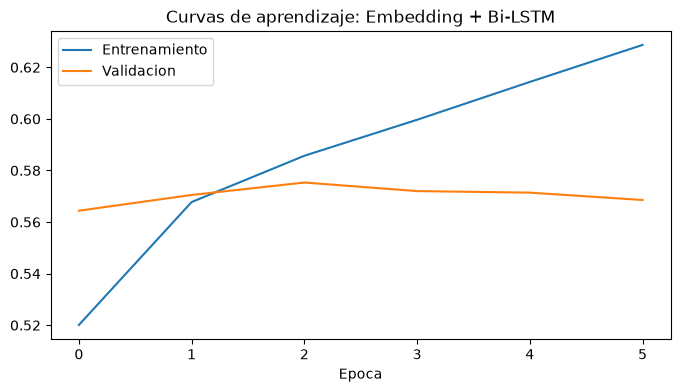

In [6]:
vec_seq = layers.TextVectorization(max_tokens=30_000, output_mode="int", output_sequence_length=128)
vec_seq.adapt(textos_train)
train_seq, val_seq, test_seq = (vectorizar(d, vec_seq, cache=True) for d in (train_ds, val_ds, test_ds))

keras.utils.set_random_seed(SEED)
entradas = keras.Input(shape=(None,), dtype="int64")
x = layers.Embedding(vec_seq.vocabulary_size(), 64)(entradas)
x = layers.Bidirectional(layers.LSTM(32))(x)
x = layers.Dropout(0.5)(x)
salidas = layers.Dense(len(CLASES), activation="softmax")(x)
modelo_seq = keras.Model(entradas, salidas)
modelo_seq.summary()

entrenar("Embedding + Bi-LSTM", "Secuencia", modelo_seq, train_seq, val_seq, test_seq)

## 4. Resultados
Exactitud de prueba de los dos modelos. Al azar sería 20 %, porque son 5 clases balanceadas.

In [7]:
resultados = pd.DataFrame(registro).T.sort_values("Exactitud prueba", ascending=False)
resultados

,Familia,Exactitud val,Exactitud prueba,Parámetros
Embedding + Bi-LSTM,Secuencia,0.575325,0.5688,1945157
Bigramas,Conjunto,0.5488,0.5532,480101


## 5. Conclusión

In [8]:
# reviso si se cumplio la regla
familia_ganadora = resultados["Familia"].iloc[0]
prediccion = "Conjunto" if cociente < 1500 else "Secuencia"
diferencia = resultados["Exactitud prueba"].iloc[0] - resultados["Exactitud prueba"].iloc[1]
print(f"Gano {resultados.index[0]} por {diferencia * 100:.1f} puntos")
print("La regla", "se cumplio" if familia_ganadora == prediccion else "no se cumplio")

Gano Embedding + Bi-LSTM por 1.6 puntos
La regla se cumplio


In [9]:
# tabla de errores del mejor modelo
mejor_modelo, test_mejor = (modelo_seq, test_seq) if familia_ganadora == "Secuencia" else (modelo_bi, test_bi)
prob = mejor_modelo.predict(test_mejor, verbose=0)
pred = prob.argmax(axis=1)
real = df_test["label"].values
distancia = np.abs(pred - real)

print(f"Errores: {np.mean(distancia > 0) * 100:.1f} % · a 1 estrella: {np.mean(distancia == 1) * 100:.1f} % · a 2 o mas: {np.mean(distancia >= 2) * 100:.1f} %")
pd.crosstab(pd.Series(real, name="Real").map(dict(enumerate(CLASES))),
            pd.Series(pred, name="Predicción").map(dict(enumerate(CLASES))))

C:\Users\efrau\OneDrive\Documents\UNIVERSIDAD\SEPTIMO\ML3\ml3\Lib\site-packages\keras\src\backend\torch\rnn.py:1076: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1479.)
  outputs, h_n, c_n = torch._VF.lstm(


Errores: 43.1 % · a 1 estrella: 37.7 % · a 2 o mas: 5.4 %


Predicción,1 estrella,2 estrellas,3 estrellas,4 estrellas,5 estrellas
Real,,,,,
1 estrella,705,237,49,6,3
2 estrellas,224,486,260,21,9
3 estrellas,51,203,495,216,35
4 estrellas,5,18,197,506,274
5 estrellas,5,8,61,274,652


In [10]:
# los errores donde el modelo estaba mas seguro
errores = pd.DataFrame({"Reseña": df_test["text"].str.replace("\n", " ").values,
                        "Real": [CLASES[i] for i in real], "Predicción": [CLASES[i] for i in pred],
                        "Seguridad": prob.max(axis=1).round(2), "Distancia": distancia})
lejanos = errores[errores.Distancia >= 2].sort_values("Seguridad", ascending=False).head(4)
vecinos = errores[errores.Distancia == 1].sort_values("Seguridad", ascending=False).head(4)
pd.concat([lejanos, vecinos])

,Reseña,Real,Predicción,Seguridad,Distancia
2752,"Vendedor responsable. Mala calidad. Son corrientes. Varios rotos, con agujero, y casi todos se desinchan al cabo de 2 horas. El brillo del anuncio no es real. Muy descontento con el producto. Ase...",3 estrellas,1 estrella,0.95,2
2776,"Mala calidad Mala calidad, solo funciona la mitad, nada recomendable",3 estrellas,1 estrella,0.92,2
4326,"Vendedor muy amable. No llegó el paquete, informé al vendedor y tuve respuesta inmediata para darme solución.",5 estrellas,1 estrella,0.90,4
2550,"Comoda Me ha encantado, es súper comoda Mi bebe tiene 9 meses, y es perfecta para ella, y muy segura. Va contenta cuando la paseo.",3 estrellas,5 estrellas,0.90,2
1794,"Desastre Aún no se cómo queda, no lo tengo montado porque hoy 18 de Mayo de 2018 es día en que supuestamente recibía el parque, y solo me han llegado 2 paquetes con los columpios y algunas madera...",2 estrellas,1 estrella,0.97,1
1682,Pesimo No se parece a la foto.. Sublimación pésima... No recomiendo,2 estrellas,1 estrella,0.95,1
1558,"Aún no ha llegado Pues no puedo valorarlo todavía, aún no lo he recibido. Ya vamos con tres días de retraso. Esperaré a ver que pasa.",2 estrellas,1 estrella,0.94,1
1633,"Mala calidad, no lo compres! Me llego el 15 de abril de 2019, hace 1 mes y medio (no llega) y ya está roto. (Con foto) De mala calidad, el anterior que compre (de otra marca) me duró 1 año. Una v...",2 estrellas,1 estrella,0.93,1


**Análisis** 

- **¿Se cumplió la regla?** Si se cumplio la regla 
- **Tipo de errores:** 
    - la mayoría (37.7%) de errores son de diferencia de una estrella, y se ve bien clara en la tabla de errores, casi como un matriz de correlaciones 
    - Los errores que no espera fueron los contradictorios, ya que en estos ultimos que se ven, son los que el modelo estaba mas seguro de que iban a ser de ese rango. Y si lees el comentario, hasta uno pensaria eso, porque son quejas muy fuertes o elogios muy marcados pero al final su calificacion es mejor o peor de lo esperado
    - Pero siguiendo con la tabla de errores los de **3 estrellas** son los mas claros, como es la calificacion intermedia, hay malas, buenas, exageradas y contradictorias. No hay nada seguro en ese rango